# Task 4: Advanced Analytics & Statistical Modeling
**ApexPlanet Software Pvt. Ltd. | Data Analytics Internship**

**Author:**Gaurav Pandey  |  **Dataset:**telico 

This notebook covers:
1. Statistical analysis (descriptive + inferential)
2. Time series analysis and forecasting
3. Customer segmentation (K-Means)
4. Predictive modeling

> **How to use:** edit only the **Configuration** cell (Section 0) so the column names match your cleaned dataset, then run all cells top to bottom. If the data file is not found, the notebook generates a small demo dataset so you can see how everything works.

## 0. Setup & Configuration

In [1]:
# --- Auto-install any missing libraries (runs safely even if everything is already installed) ---
import sys, subprocess, importlib

REQUIRED = {            # import name : pip package name
    "numpy": "numpy", "pandas": "pandas", "matplotlib": "matplotlib", "seaborn": "seaborn",
    "scipy": "scipy", "sklearn": "scikit-learn", "statsmodels": "statsmodels",
}
missing = []
for module, pip_name in REQUIRED.items():
    try:
        importlib.import_module(module)
    except ImportError:
        missing.append(pip_name)

if missing:
    print("Installing missing packages:", missing)
    try:
        subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", *missing])
        importlib.invalidate_caches()
        print("Installation complete.")
    except Exception as e:
        print("Automatic install failed:", e)
        print("Run this in a terminal / Anaconda Prompt, then restart the kernel:")
        print("   pip install " + " ".join(missing))
else:
    print("All required packages are already installed.")

Installing missing packages: ['scipy', 'scikit-learn', 'statsmodels']
Installation complete.


In [2]:
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression, LogisticRegression
from sklearn.tree import DecisionTreeClassifier, DecisionTreeRegressor
from sklearn.metrics import (silhouette_score, mean_absolute_error, mean_squared_error, r2_score,
                             accuracy_score, precision_score, recall_score, f1_score,
                             roc_auc_score, confusion_matrix, classification_report)

sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (9, 5)
RANDOM_STATE = 42
results = {}   # key metrics are stored here for the final summary / LinkedIn post

In [3]:
# ============ CONFIGURATION: EDIT THESE TO MATCH YOUR DATASET ============
DATA_PATH   = "../data/processed/cleaned_data.csv"   # your cleaned dataset from Task 1

DATE_COL    = "date"        # date column for time series (set to None if you have no date column)
VALUE_COL   = "sales"       # main numeric column (sales, revenue, charges ...)
GROUP_COL   = "gender"      # categorical column with 2 groups -> t-test on VALUE_COL
CAT_COL     = "category"    # categorical column with 3+ groups -> ANOVA on VALUE_COL
CAT_COL_2   = "region"      # second categorical column -> chi-square with CAT_COL
TARGET_COL  = "churn"       # prediction target: churn (category) OR sales (number)
CLUSTER_COLS = ["tenure", "quantity", "sales"]       # numeric columns used for segmentation
DROP_COLS   = ["customer_id"]                        # ID-like columns to exclude from modeling
# ==========================================================================

In [4]:
import os

def make_demo_data(n=3000, seed=42):
    rng = np.random.default_rng(seed)
    dates = pd.to_datetime("2022-01-01") + pd.to_timedelta(rng.integers(0, 1095, n), unit="D")
    category = rng.choice(["Electronics", "Clothing", "Grocery", "Home"], n, p=[.25, .25, .3, .2])
    region = rng.choice(["North", "South", "East", "West"], n)
    gender = rng.choice(["Male", "Female"], n)
    tenure = rng.integers(1, 72, n)
    quantity = rng.integers(1, 10, n)
    base = pd.Series(category).map({"Electronics": 180, "Clothing": 90, "Grocery": 50, "Home": 120}).values
    season = 1 + 0.25 * np.sin(2 * np.pi * pd.DatetimeIndex(dates).month / 12)
    sales = base * quantity * season * rng.normal(1, 0.15, n)
    churn_p = 1 / (1 + np.exp(0.05 * tenure - 1.2 + 0.0015 * (200 - sales)))
    churn = np.where(rng.random(n) < churn_p, "Yes", "No")
    return pd.DataFrame({"customer_id": range(1, n + 1), "date": dates, "gender": gender,
                         "category": category, "region": region, "tenure": tenure,
                         "quantity": quantity, "sales": sales.round(2), "churn": churn})

if os.path.exists(DATA_PATH):
    df = pd.read_csv(DATA_PATH)
    print(f"Loaded {DATA_PATH}")
else:
    df = make_demo_data()
    print("DATA FILE NOT FOUND -> using DEMO data. Set DATA_PATH to use your own dataset.")

if DATE_COL and DATE_COL in df.columns:
    df[DATE_COL] = pd.to_datetime(df[DATE_COL], errors="coerce")
    df = df.dropna(subset=[DATE_COL])

print(df.shape)
df.head()

DATA FILE NOT FOUND -> using DEMO data. Set DATA_PATH to use your own dataset.
(3000, 9)


,customer_id,date,gender,category,region,tenure,quantity,sales,churn
0,1,2022-04-08,Female,Grocery,South,6,7,553.47,No
1,2,2024-04-27,Male,Home,North,36,8,1308.37,No
2,3,2023-12-18,Male,Clothing,East,41,2,159.76,Yes
3,4,2023-04-26,Male,Clothing,South,53,3,259.48,No
4,5,2023-04-20,Female,Home,West,41,1,158.39,Yes


In [5]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 3000 entries, 0 to 2999
Data columns (total 9 columns):
 #   Column       Non-Null Count  Dtype         
---  ------       --------------  -----         
 0   customer_id  3000 non-null   int64         
 1   date         3000 non-null   datetime64[us]
 2   gender       3000 non-null   str           
 3   category     3000 non-null   str           
 4   region       3000 non-null   str           
 5   tenure       3000 non-null   int64         
 6   quantity     3000 non-null   int64         
 7   sales        3000 non-null   float64       
 8   churn        3000 non-null   str           
dtypes: datetime64[us](1), float64(1), int64(3), str(4)
memory usage: 211.1 KB


## 1. Statistical Analysis (Days 28-30)
### 1.1 Descriptive statistics
Mean, median, mode, variance, standard deviation, skewness and kurtosis for the main numeric variable.

,sales
Mean,530.287
Median,405.025
Mode,90.870
Variance,181133.230
Std Dev,425.597
Skewness,1.328
Kurtosis,1.532


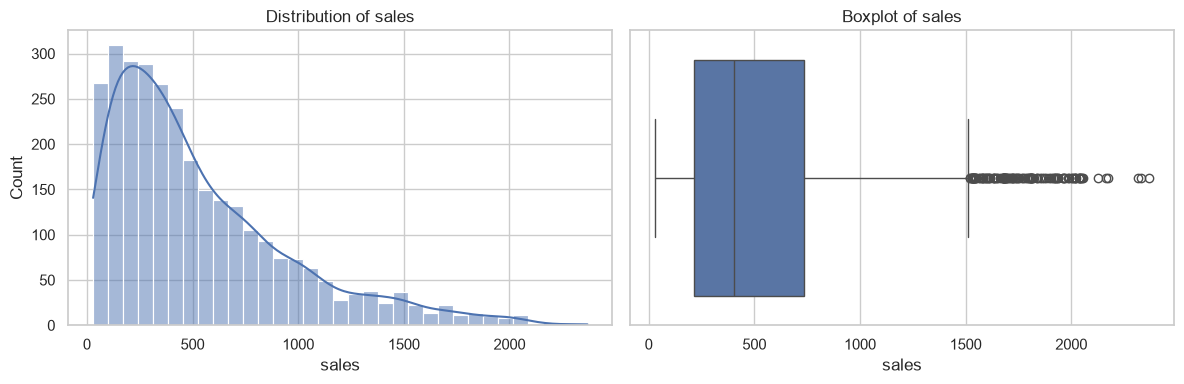

In [6]:
col = df[VALUE_COL].dropna()
desc = pd.Series({
    "Mean": col.mean(), "Median": col.median(), "Mode": col.mode().iloc[0],
    "Variance": col.var(), "Std Dev": col.std(),
    "Skewness": col.skew(), "Kurtosis": col.kurt()
})
display(desc.round(3).to_frame(VALUE_COL))

fig, ax = plt.subplots(1, 2, figsize=(12, 4))
sns.histplot(col, kde=True, ax=ax[0]); ax[0].set_title(f"Distribution of {VALUE_COL}")
sns.boxplot(x=col, ax=ax[1]); ax[1].set_title(f"Boxplot of {VALUE_COL}")
plt.tight_layout(); plt.show()

**Interpretation:** *(write here)* Is the distribution skewed? Positive skew means a long right tail (a few very large values). What does this mean for the business?

### 1.2 Confidence interval (95%) for the mean

In [7]:
ci_low, ci_high = stats.t.interval(0.95, len(col) - 1, loc=col.mean(), scale=stats.sem(col))
print(f"95% CI for mean {VALUE_COL}: ({ci_low:.2f}, {ci_high:.2f})")
results["ci_95"] = (round(float(ci_low), 2), round(float(ci_high), 2))

95% CI for mean sales: (515.05, 545.52)


### 1.3 Hypothesis testing
Significance level **alpha = 0.05**. If p < 0.05 we reject H0.

**Test 1: Independent t-test** (two groups)
- H0: the mean of `VALUE_COL` is the same in both groups
- H1: the means are different

In [8]:
groups = df[GROUP_COL].value_counts().index[:2]
g1 = df.loc[df[GROUP_COL] == groups[0], VALUE_COL].dropna()
g2 = df.loc[df[GROUP_COL] == groups[1], VALUE_COL].dropna()

t_stat, p_t = stats.ttest_ind(g1, g2, equal_var=False)   # Welch's t-test
print(f"Groups: {groups[0]} (mean={g1.mean():.2f}) vs {groups[1]} (mean={g2.mean():.2f})")
print(f"t = {t_stat:.3f}, p-value = {p_t:.4f}")
print("Conclusion:", "Reject H0 -> significant difference" if p_t < 0.05 else "Fail to reject H0 -> no significant difference")
results["ttest_p"] = round(p_t, 4)

Groups: Male (mean=523.43) vs Female (mean=537.45)
t = -0.901, p-value = 0.3678
Conclusion: Fail to reject H0 -> no significant difference


**Test 2: Chi-square test of independence** (two categorical variables)
- H0: `CAT_COL` and `CAT_COL_2` are independent
- H1: they are associated

In [9]:
ct = pd.crosstab(df[CAT_COL], df[CAT_COL_2])
chi2, p_chi, dof, expected = stats.chi2_contingency(ct)
print(f"chi2 = {chi2:.3f}, dof = {dof}, p-value = {p_chi:.4f}")
print("Conclusion:", "Reject H0 -> variables are associated" if p_chi < 0.05 else "Fail to reject H0 -> no evidence of association")
results["chi2_p"] = round(p_chi, 4)

chi2 = 9.965, dof = 9, p-value = 0.3533
Conclusion: Fail to reject H0 -> no evidence of association


**Test 3: One-way ANOVA** (3 or more groups)
- H0: mean `VALUE_COL` is equal across all `CAT_COL` groups
- H1: at least one group mean differs

F = 512.121, p-value = 0.0000
Conclusion: Reject H0 -> at least one group differs


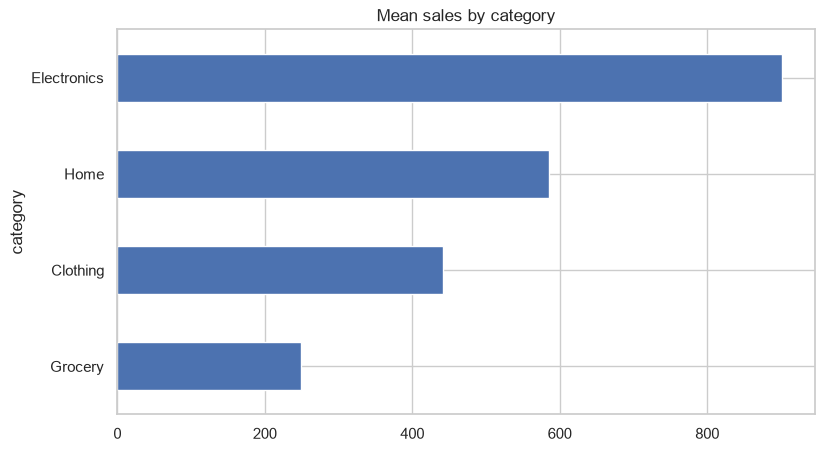

In [10]:
samples = [g[VALUE_COL].dropna().values for _, g in df.groupby(CAT_COL)]
f_stat, p_anova = stats.f_oneway(*samples)
print(f"F = {f_stat:.3f}, p-value = {p_anova:.4f}")
print("Conclusion:", "Reject H0 -> at least one group differs" if p_anova < 0.05 else "Fail to reject H0")
results["anova_p"] = round(p_anova, 4)

df.groupby(CAT_COL)[VALUE_COL].mean().sort_values().plot(kind="barh", title=f"Mean {VALUE_COL} by {CAT_COL}")
plt.show()

### 1.4 Correlation vs causation

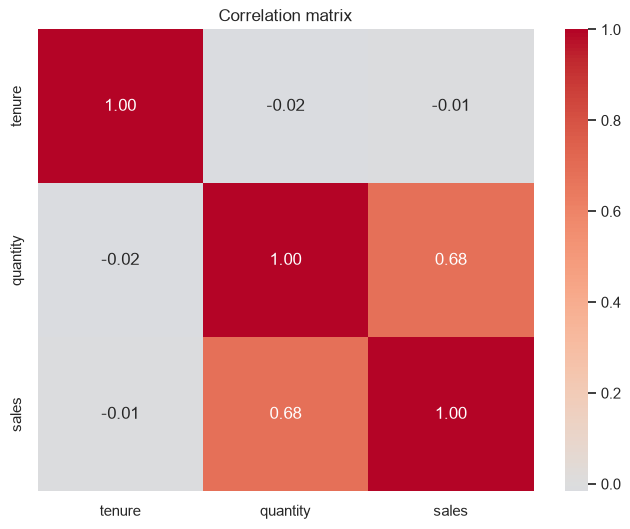

correlation
quantity sales        0.680123
tenure   quantity    -0.016627
         sales       -0.010468

In [11]:
num_df = df.select_dtypes(include="number").drop(columns=[c for c in DROP_COLS if c in df.columns])
corr = num_df.corr()
plt.figure(figsize=(8, 6))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", center=0)
plt.title("Correlation matrix"); plt.show()

# strongest pairs
pairs = corr.where(np.triu(np.ones(corr.shape), k=1).astype(bool)).stack().dropna().sort_values(key=abs, ascending=False)
display(pairs.head(5).to_frame("correlation"))

**Business implications (write your own):**
- Correlation shows two variables move together; it does **not** prove one causes the other. Hidden (confounding) variables can create misleading links.
- Summarize: which groups differ significantly? Which categories perform best? What action would you recommend?

## 2. Time Series Analysis (Days 31-33)
Convert to a datetime index, resample, decompose, test stationarity, smooth, forecast with ARIMA/SARIMA and evaluate.

Time series (monthly): 36 points, 2022-01-31 to 2024-12-31


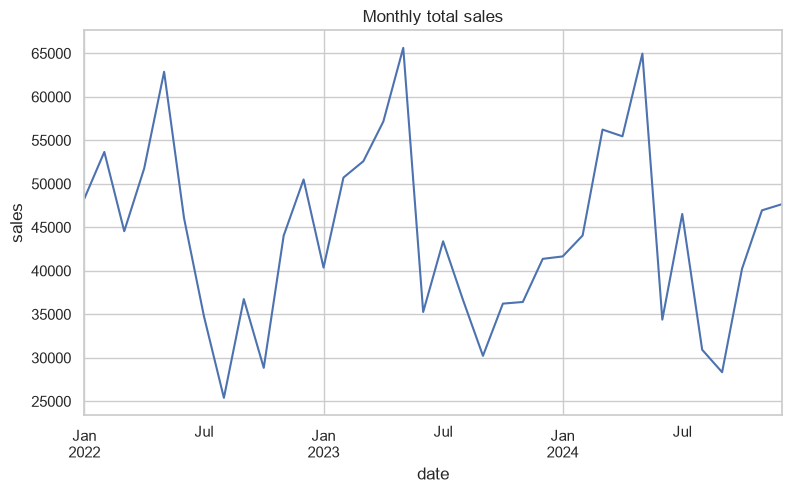

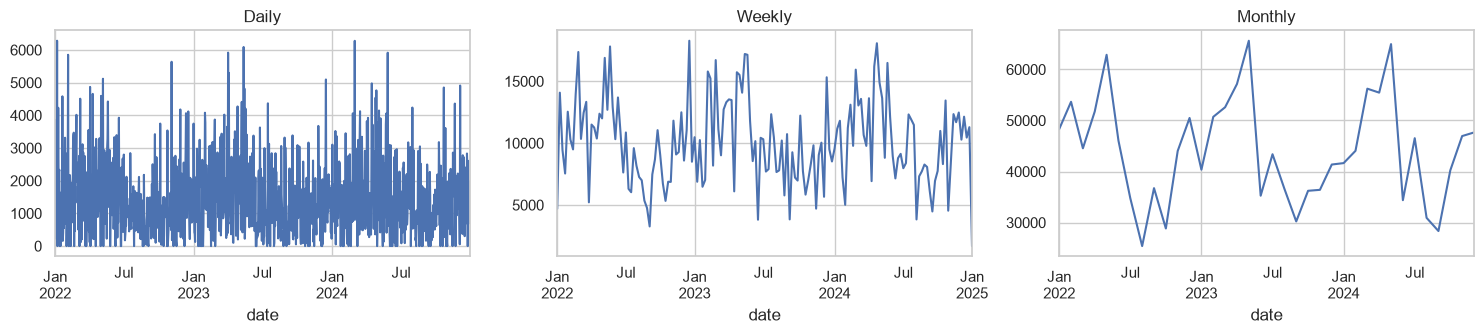

In [12]:
HAS_TS = bool(DATE_COL) and DATE_COL in df.columns
if HAS_TS:
    span_days = (df[DATE_COL].max() - df[DATE_COL].min()).days
    # pick a resampling frequency that gives enough points
    MONTH_END = "ME" if tuple(int(x) for x in pd.__version__.split(".")[:2]) >= (2, 2) else "M"
    if span_days >= 730:   FREQ, SEASON, label = MONTH_END, 12, "monthly"
    elif span_days >= 150: FREQ, SEASON, label = "W", None, "weekly"
    else:                  FREQ, SEASON, label = "D", None, "daily"

    ts = df.set_index(DATE_COL)[VALUE_COL].sort_index().resample(FREQ).sum()
    ts = ts[ts > 0] if (ts == 0).any() else ts
    print(f"Time series ({label}): {len(ts)} points, {ts.index.min().date()} to {ts.index.max().date()}")
    ts.plot(title=f"{label.title()} total {VALUE_COL}"); plt.ylabel(VALUE_COL); plt.show()

    # resampling comparison
    fig, ax = plt.subplots(1, 3, figsize=(15, 3.5))
    for a, f, n in zip(ax, ["D", "W", MONTH_END], ["Daily", "Weekly", "Monthly"]):
        df.set_index(DATE_COL)[VALUE_COL].resample(f).sum().plot(ax=a, title=n)
    plt.tight_layout(); plt.show()
else:
    print("No date column configured -> time series section skipped.")

### 2.1 Decomposition (trend, seasonality, residual)

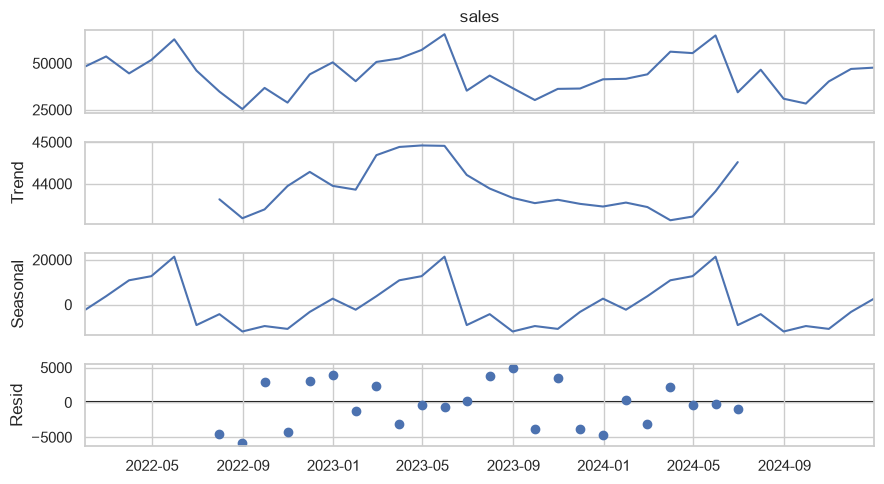

In [13]:
if HAS_TS:
    from statsmodels.tsa.seasonal import seasonal_decompose
    period = SEASON if SEASON and len(ts) >= 2 * SEASON else (4 if len(ts) >= 8 else None)
    if period:
        seasonal_decompose(ts, model="additive", period=period).plot()
        plt.tight_layout(); plt.show()
    else:
        print("Series too short for decomposition.")

### 2.2 Stationarity (ADF test)
- H0: series is non-stationary
- p < 0.05 means the series is stationary

In [14]:
if HAS_TS:
    from statsmodels.tsa.stattools import adfuller
    adf_p = adfuller(ts.dropna())[1]
    print(f"ADF p-value (original): {adf_p:.4f} ->", "stationary" if adf_p < 0.05 else "non-stationary")
    adf_p_diff = adfuller(ts.diff().dropna())[1]
    print(f"ADF p-value (1st difference): {adf_p_diff:.4f} ->", "stationary" if adf_p_diff < 0.05 else "non-stationary")

ADF p-value (original): 0.0104 -> stationary
ADF p-value (1st difference): 0.0000 -> stationary


### 2.3 Smoothing (moving average, exponential smoothing)

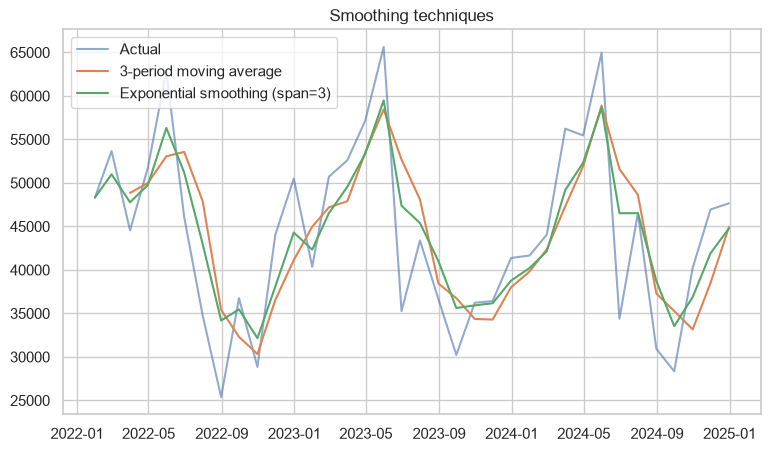

In [15]:
if HAS_TS:
    plt.plot(ts, label="Actual", alpha=0.6)
    plt.plot(ts.rolling(3).mean(), label="3-period moving average")
    plt.plot(ts.ewm(span=3, adjust=False).mean(), label="Exponential smoothing (span=3)")
    plt.legend(); plt.title("Smoothing techniques"); plt.show()

### 2.4 Forecasting with ARIMA / SARIMA

c:\Users\Gaurav Pandey\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\statsmodels\tsa\statespace\sarimax.py:1022: EstimationWarning: Too few observations to estimate starting parameters for seasonal ARMA. All parameters except for variances will be set to zeros.
  self._conditional_sum_squares(


SARIMA(1,1,1)x(1,1,1,12)
MAE = 4,750.10 | RMSE = 5,876.36 | MAPE = 11.34%  (accuracy ~ 88.7%)


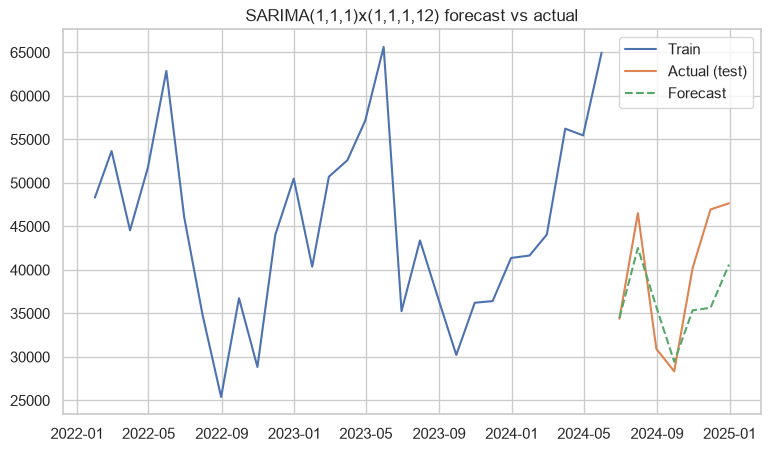

c:\Users\Gaurav Pandey\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\statsmodels\tsa\statespace\sarimax.py:1022: EstimationWarning: Too few observations to estimate starting parameters for seasonal ARMA. All parameters except for variances will be set to zeros.
  self._conditional_sum_squares(


,forecast
2025-01-31,50088.32
2025-02-28,53979.33
2025-03-31,62235.78
2025-04-30,63004.35
2025-05-31,72007.85
2025-06-30,43964.21


In [16]:
if HAS_TS:
    from statsmodels.tsa.statespace.sarimax import SARIMAX

    n_test = max(3, int(len(ts) * 0.2))
    train, test = ts.iloc[:-n_test], ts.iloc[-n_test:]

    if SEASON and len(train) >= 2 * SEASON:
        model = SARIMAX(train, order=(1, 1, 1), seasonal_order=(1, 1, 1, SEASON),
                        enforce_stationarity=False, enforce_invertibility=False)
        name = f"SARIMA(1,1,1)x(1,1,1,{SEASON})"
    else:
        model = SARIMAX(train, order=(1, 1, 1))
        name = "ARIMA(1,1,1)"
    fit = model.fit(disp=False)
    pred = fit.forecast(n_test)

    mae  = mean_absolute_error(test, pred)
    rmse = np.sqrt(mean_squared_error(test, pred))
    mape = (np.abs((test - pred) / test)).mean() * 100
    print(f"{name}\nMAE = {mae:,.2f} | RMSE = {rmse:,.2f} | MAPE = {mape:.2f}%  (accuracy ~ {100 - mape:.1f}%)")
    results["ts_model"] = name
    results["ts_mape"] = round(mape, 2)
    results["ts_accuracy"] = round(100 - mape, 1)

    plt.plot(train, label="Train"); plt.plot(test, label="Actual (test)")
    plt.plot(pred, label="Forecast", linestyle="--")
    plt.legend(); plt.title(f"{name} forecast vs actual"); plt.show()

    # forecast the future
    full = SARIMAX(ts, order=model.order, seasonal_order=model.seasonal_order).fit(disp=False)
    future = full.forecast(6)
    display(future.round(2).to_frame("forecast"))

## 3. Customer Segmentation - K-Means (Days 34-36)

In [17]:
cluster_cols = [c for c in CLUSTER_COLS if c in df.columns]
seg = df[cluster_cols].dropna().copy()
X_scaled = StandardScaler().fit_transform(seg)
print("Features used:", cluster_cols)

Features used: ['tenure', 'quantity', 'sales']


### 3.1 Choosing K: elbow method + silhouette score

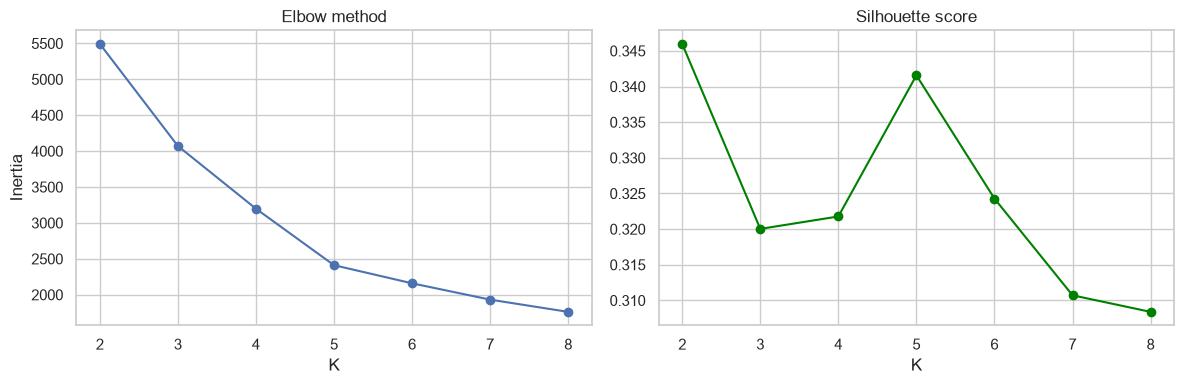

K with best silhouette score: 2


In [18]:
K_RANGE = range(2, 9)
inertias, sils = [], []
for k in K_RANGE:
    km = KMeans(n_clusters=k, random_state=RANDOM_STATE, n_init=10).fit(X_scaled)
    inertias.append(km.inertia_)
    sils.append(silhouette_score(X_scaled, km.labels_, sample_size=min(5000, len(X_scaled)), random_state=RANDOM_STATE))

fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].plot(list(K_RANGE), inertias, marker="o"); ax[0].set_title("Elbow method"); ax[0].set_xlabel("K"); ax[0].set_ylabel("Inertia")
ax[1].plot(list(K_RANGE), sils, marker="o", color="green"); ax[1].set_title("Silhouette score"); ax[1].set_xlabel("K")
plt.tight_layout(); plt.show()

best_k = list(K_RANGE)[int(np.argmax(sils))]
print("K with best silhouette score:", best_k)

In [19]:
# You can override best_k after looking at the elbow plot, e.g. K = 4
K = best_k
kmeans = KMeans(n_clusters=K, random_state=RANDOM_STATE, n_init=10).fit(X_scaled)
seg["cluster"] = kmeans.labels_
results["n_clusters"] = K
results["silhouette"] = round(silhouette_score(X_scaled, kmeans.labels_, sample_size=min(5000, len(X_scaled)), random_state=RANDOM_STATE), 3)
print(seg["cluster"].value_counts().sort_index())

cluster
0    1667
1    1333
Name: count, dtype: int64


### 3.2 Cluster profiles

,tenure,quantity,sales,size,share_%
cluster,,,,,
0,36.59,3.01,265.52,1667,55.6
1,35.60,7.33,861.40,1333,44.4


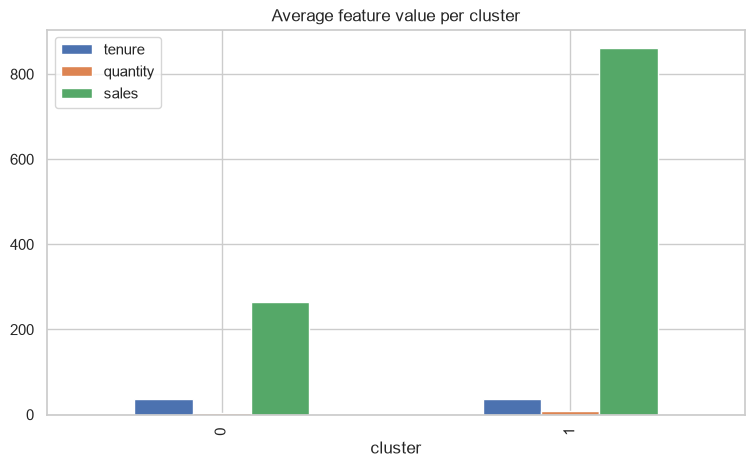

In [20]:
profile = seg.groupby("cluster")[cluster_cols].mean().round(2)
profile["size"] = seg["cluster"].value_counts().sort_index()
profile["share_%"] = (profile["size"] / profile["size"].sum() * 100).round(1)
display(profile)

profile[cluster_cols].plot(kind="bar", title="Average feature value per cluster"); plt.show()

### 3.3 PCA visualization (2D)

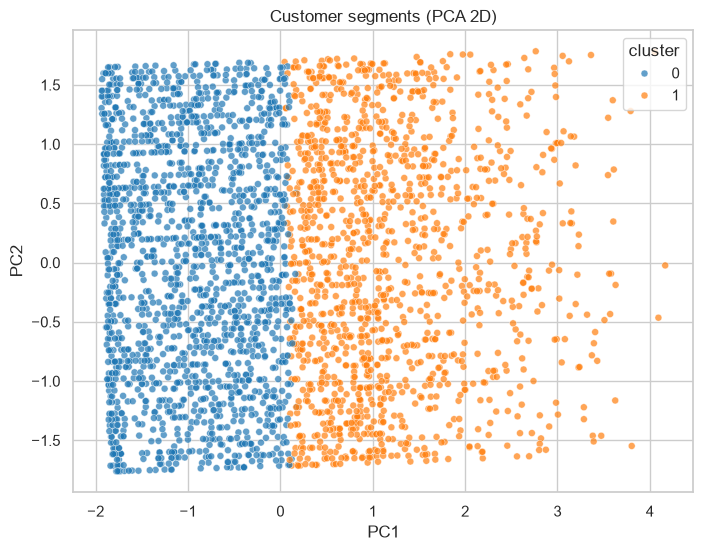

In [21]:
pcs = PCA(n_components=2, random_state=RANDOM_STATE).fit_transform(X_scaled)
plt.figure(figsize=(8, 6))
sns.scatterplot(x=pcs[:, 0], y=pcs[:, 1], hue=seg["cluster"], palette="tab10", alpha=0.7, s=25)
plt.title("Customer segments (PCA 2D)"); plt.xlabel("PC1"); plt.ylabel("PC2"); plt.show()

### 3.4 Segment names & recommendations
Look at the profile table above and fill in (example):

| Cluster | Name | Behaviour | Recommendation |
|---|---|---|---|
| 0 | *e.g. High-value loyal* | high spend, long tenure | loyalty rewards, early access |
| 1 | *e.g. New customers* | low tenure, low spend | onboarding offers, welcome emails |
| 2 | *e.g. At-risk* | low spend, mid tenure | win-back discounts |

## 4. Predictive Modeling - Basic (Days 37-38)
The task type is detected automatically: a categorical target (e.g. churn) -> **classification**; a numeric target (e.g. sales) -> **regression**.

In [22]:
data = df.drop(columns=[c for c in DROP_COLS if c in df.columns]).dropna().copy()
if DATE_COL in data.columns:   # use date parts instead of raw date
    data["year"] = data[DATE_COL].dt.year
    data["month"] = data[DATE_COL].dt.month
    data = data.drop(columns=[DATE_COL])

y_raw = data[TARGET_COL]
is_classification = (y_raw.dtype == "object") or (y_raw.dtype == "bool") or (y_raw.nunique() <= 10)
print("Target:", TARGET_COL, "->", "CLASSIFICATION" if is_classification else "REGRESSION")

X = pd.get_dummies(data.drop(columns=[TARGET_COL]), drop_first=True)

if is_classification:
    classes = sorted(y_raw.astype(str).unique())
    positive = "Yes" if "Yes" in classes else ("1" if "1" in classes else classes[-1])
    y = (y_raw.astype(str) == positive).astype(int)
    print("Positive class:", positive, "| class balance:\n", y.value_counts(normalize=True).round(3))
else:
    y = y_raw

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=RANDOM_STATE, stratify=y if is_classification else None)
print("Train:", X_train.shape, "Test:", X_test.shape)

Target: churn -> CLASSIFICATION
Positive class: Yes | class balance:
 churn
0    0.545
1    0.455
Name: proportion, dtype: float64
Train: (2400, 12) Test: (600, 12)


### 4.1 Models and evaluation

,Accuracy,Precision,Recall,F1,ROC-AUC
Model,,,,,
Logistic Regression,0.710,0.690,0.659,0.674,0.756
Decision Tree,0.677,0.635,0.681,0.657,0.730


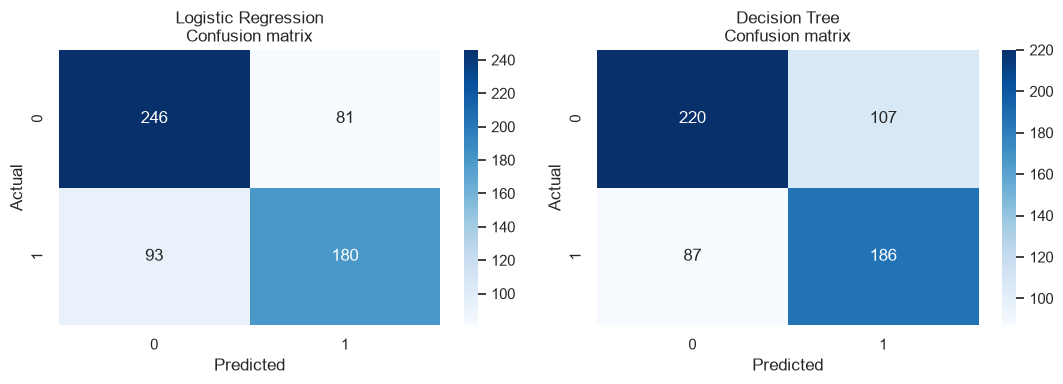

              precision    recall  f1-score   support

           0       0.72      0.67      0.69       327
           1       0.63      0.68      0.66       273

    accuracy                           0.68       600
   macro avg       0.68      0.68      0.68       600
weighted avg       0.68      0.68      0.68       600



In [23]:
if is_classification:
    scaler = StandardScaler().fit(X_train)
    models = {
        "Logistic Regression": (LogisticRegression(max_iter=2000, class_weight="balanced"), True),
        "Decision Tree":       (DecisionTreeClassifier(max_depth=5, class_weight="balanced", random_state=RANDOM_STATE), False),
    }
    rows, fitted = [], {}
    for name, (m, needs_scale) in models.items():
        Xtr = scaler.transform(X_train) if needs_scale else X_train
        Xte = scaler.transform(X_test)  if needs_scale else X_test
        m.fit(Xtr, y_train)
        pred = m.predict(Xte); proba = m.predict_proba(Xte)[:, 1]
        rows.append({"Model": name,
                     "Accuracy": accuracy_score(y_test, pred), "Precision": precision_score(y_test, pred, zero_division=0),
                     "Recall": recall_score(y_test, pred), "F1": f1_score(y_test, pred),
                     "ROC-AUC": roc_auc_score(y_test, proba)})
        fitted[name] = (m, Xte, pred)
    res = pd.DataFrame(rows).set_index("Model").round(3)
    display(res)

    best = res["Recall"].idxmax()
    results["best_model"] = best
    results["recall"] = res.loc[best, "Recall"]
    results["roc_auc"] = res.loc[best, "ROC-AUC"]

    fig, ax = plt.subplots(1, 2, figsize=(11, 4))
    for a, (name, (m, Xte, pred)) in zip(ax, fitted.items()):
        sns.heatmap(confusion_matrix(y_test, pred), annot=True, fmt="d", cmap="Blues", ax=a)
        a.set_title(f"{name}\nConfusion matrix"); a.set_xlabel("Predicted"); a.set_ylabel("Actual")
    plt.tight_layout(); plt.show()
    print(classification_report(y_test, fitted[best][2]))
else:
    models = {"Linear Regression": LinearRegression(),
              "Decision Tree": DecisionTreeRegressor(max_depth=5, random_state=RANDOM_STATE)}
    rows, fitted = [], {}
    for name, m in models.items():
        m.fit(X_train, y_train); pred = m.predict(X_test)
        rows.append({"Model": name, "R2": r2_score(y_test, pred),
                     "MAE": mean_absolute_error(y_test, pred),
                     "RMSE": np.sqrt(mean_squared_error(y_test, pred))})
        fitted[name] = (m, X_test, pred)
    res = pd.DataFrame(rows).set_index("Model").round(3)
    display(res)
    best = res["R2"].idxmax()
    results["best_model"] = best; results["r2"] = res.loc[best, "R2"]

    plt.scatter(y_test, fitted[best][2], alpha=0.4)
    plt.plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], "r--")
    plt.xlabel("Actual"); plt.ylabel("Predicted"); plt.title(f"{best}: actual vs predicted"); plt.show()

### 4.2 ROC curve (classification only)

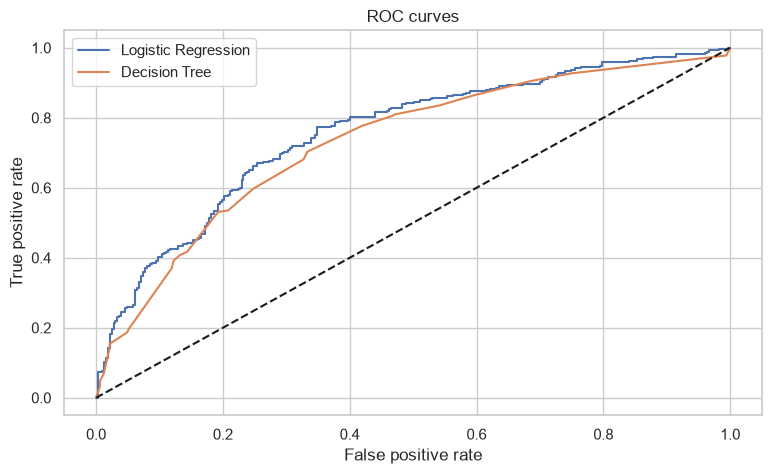

In [24]:
if is_classification:
    from sklearn.metrics import roc_curve
    for name, (m, Xte, pred) in fitted.items():
        fpr, tpr, _ = roc_curve(y_test, m.predict_proba(Xte)[:, 1])
        plt.plot(fpr, tpr, label=name)
    plt.plot([0, 1], [0, 1], "k--"); plt.xlabel("False positive rate"); plt.ylabel("True positive rate")
    plt.legend(); plt.title("ROC curves"); plt.show()

### 4.3 Feature importance

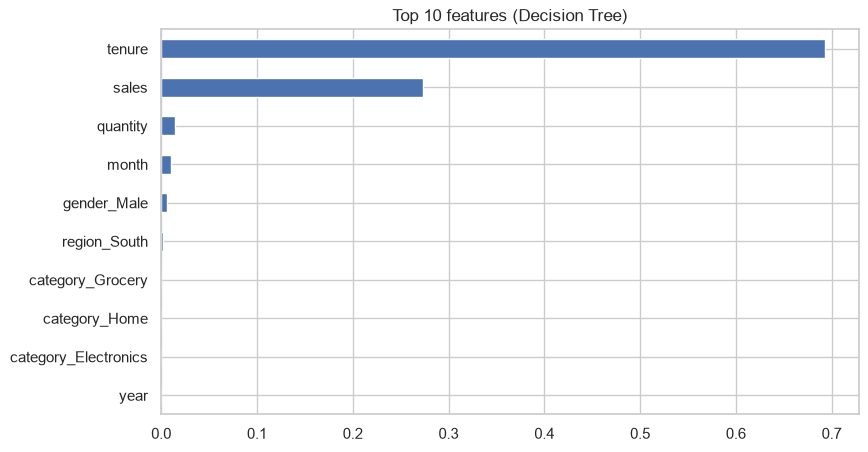

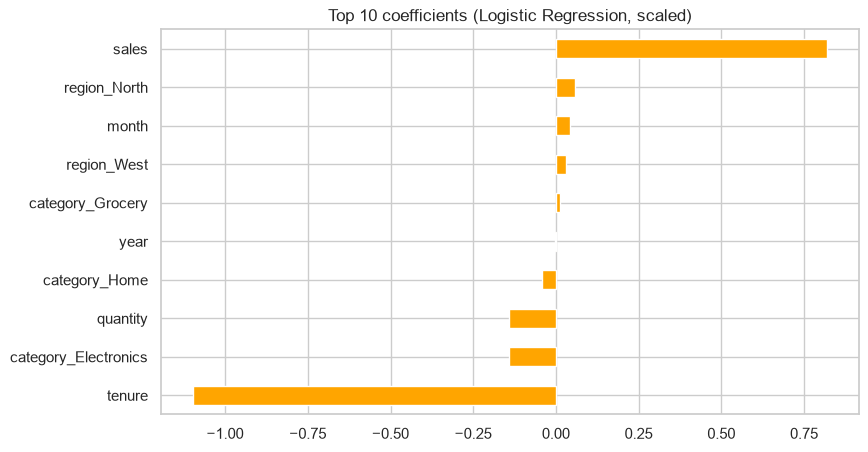

In [25]:
tree_name = "Decision Tree"
tree = fitted[tree_name][0]
imp = pd.Series(tree.feature_importances_, index=X.columns).sort_values(ascending=False).head(10)
imp.sort_values().plot(kind="barh", title="Top 10 features (Decision Tree)"); plt.show()

if is_classification:
    lr = fitted["Logistic Regression"][0]
    coef = pd.Series(lr.coef_[0], index=X.columns).sort_values(key=abs, ascending=False).head(10)
    coef.sort_values().plot(kind="barh", color="orange", title="Top 10 coefficients (Logistic Regression, scaled)"); plt.show()

### 4.4 Model limitations (edit to match your results)
- Class imbalance can inflate accuracy; focus on recall, F1 and ROC-AUC.
- Only the available features are used; important drivers (e.g. customer satisfaction, competitor offers) may be missing.
- Decision trees can overfit; limiting depth helps, but results can still change with different data splits.
- Linear/logistic models assume linear relationships.
- Time series forecasts assume past patterns continue and are less reliable far into the future.
- Correlation found by models does not prove causation.

## 5. Summary of Results (for your README and LinkedIn post)

In [26]:
for k, v in results.items():
    print(f"{k:15s}: {v}")

print("\n--- LinkedIn caption draft ---")
ts_txt = f"time series forecasting ({results.get('ts_model', 'ARIMA')}, MAPE {results.get('ts_mape', 'n/a')}%)"
if is_classification:
    pred_txt = f"{TARGET_COL} prediction ({results.get('best_model')}, recall {results.get('recall', 0):.0%}, ROC-AUC {results.get('roc_auc', 0):.2f})"
else:
    pred_txt = f"{TARGET_COL} prediction ({results.get('best_model')}, R2 {results.get('r2', 0):.2f})"
print(f"Task 4 complete at @Apexplanet! Performed hypothesis testing, {ts_txt}, "
      f"customer segmentation ({results.get('n_clusters')} clusters), and {pred_txt}. #DataScience #MachineLearning")

ci_95          : (515.05, 545.52)
ttest_p        : 0.3678
chi2_p         : 0.3533
anova_p        : 0.0
ts_model       : SARIMA(1,1,1)x(1,1,1,12)
ts_mape        : 11.34
ts_accuracy    : 88.7
n_clusters     : 2
silhouette     : 0.346
best_model     : Decision Tree
recall         : 0.681
roc_auc        : 0.73

--- LinkedIn caption draft ---
Task 4 complete at @Apexplanet! Performed hypothesis testing, time series forecasting (SARIMA(1,1,1)x(1,1,1,12), MAPE 11.34%), customer segmentation (2 clusters), and churn prediction (Decision Tree, recall 68%, ROC-AUC 0.73). #DataScience #MachineLearning
